# 06. 중간발표 예비 결과 (G0)
검증·보정 구간 기준 **예비 결과**. 2025 시험 구간은 열지 않았다. 2024-02 조직 코드 변경 전후 혼재, 공휴일 대조 전, 신뢰구간 없음.
입력: `results/*.csv`, `data/splits/`(구급 개인 기록이 들어 있어 커밋 금지). 그림과 표는 `발표자료/중간발표/`에 저장한다.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
OUT = Path("work/figures/06"); TBL = Path("work/tables/06")
OUT_T = OUT; TBL_T = TBL
metrics = pd.read_csv("results/midterm_metrics.csv")
calib = pd.read_csv("results/calibration_midterm.csv")
metrics["variant"] = metrics.train_years.astype(str) + " / 보정 " + metrics.calib_months.astype(str)
BASE = "2019-2022 / 보정 1-12"
OUT.mkdir(parents=True, exist_ok=True); TBL.mkdir(parents=True, exist_ok=True)

## 1. 연도별 정제 깔때기 (서울 전체 → 라벨 코호트)

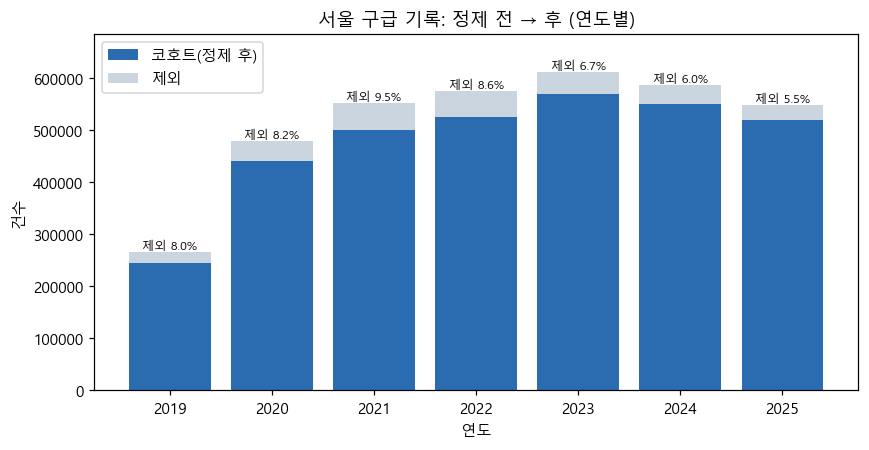

In [2]:
f = pd.read_csv("results/ems_cleaning_funnel_by_year.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(f.year, f.cohort, label="코호트(정제 후)", color="#2b6cb0")
ax.bar(f.year, f.excluded, bottom=f.cohort, label="제외", color="#cbd5e0")
for y, c, e, r in zip(f.year, f.cohort, f.excluded, f.excluded_rate):
    ax.text(y, c + e, f"제외 {r:.1%}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("연도"); ax.set_ylabel("건수"); ax.set_title("서울 구급 기록: 정제 전 → 후 (연도별)")
ax.legend(); ax.set_ylim(0, f.seoul_all.max() * 1.12)
fig.tight_layout(); fig.savefig(OUT / "01_정제_깔때기.png"); plt.show()

## 2. 연도별 8분 초과율 (안전센터만, 학습·검증·보정 분할 기준)

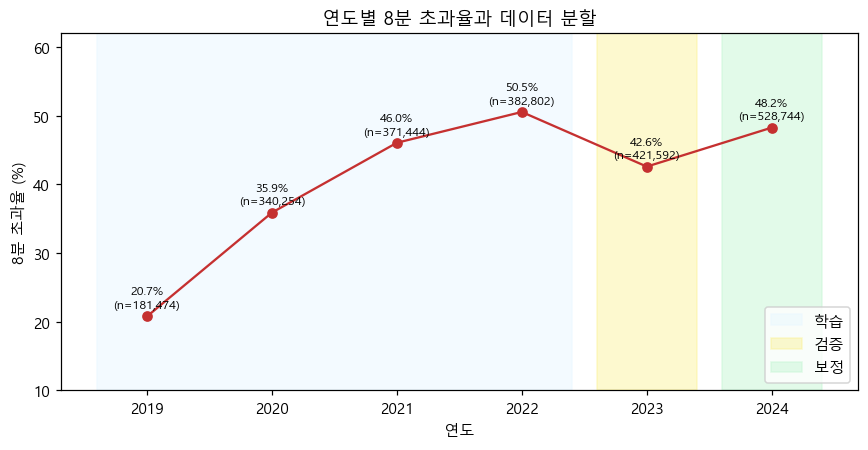

In [3]:
sp = pd.concat([pd.read_parquet(f"data/splits/train2019-2022_calib1-12/{s}.parquet", columns=["date", "y_late"]) for s in ["train", "valid", "calib"]])
sp["year"] = pd.to_datetime(sp["date"]).dt.year
yr = sp.groupby("year").y_late.agg(["mean", "size"]).reset_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(yr.year, yr["mean"] * 100, marker="o", color="#c53030")
for y, m, n in zip(yr.year, yr["mean"], yr["size"]):
    ax.text(y, m * 100 + 1.2, f"{m:.1%}\n(n={n:,})", ha="center", fontsize=8)
ax.axvspan(2018.6, 2022.4, color="#ebf8ff", alpha=.6, label="학습"); ax.axvspan(2022.6, 2023.4, color="#faf089", alpha=.4, label="검증"); ax.axvspan(2023.6, 2024.4, color="#c6f6d5", alpha=.5, label="보정")
ax.set_ylim(10, 62); ax.set_xlabel("연도"); ax.set_ylabel("8분 초과율 (%)"); ax.set_title("연도별 8분 초과율과 데이터 분할")
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(OUT / "02_연도별_8분초과율.png"); plt.show()
yr.to_csv(TBL / "연도별_8분초과율_안전센터.csv", index=False, encoding="utf-8-sig")

## 3. 모델 성능 표 (보정 구간, 보정 전 vs cross-fit 보정 후)

In [4]:
a = metrics[(metrics.variant == BASE) & (metrics.group == "all") & (metrics.split == "calib") & (metrics.stage.isin(["raw", "crossfit"]))].copy()
a["거리"] = a.dist_mode.where(a.dist_mode.isin(["D+", "D-"]), a.dist.map({"dplus": "D+", "dminus": "D-"}))
tab = a.pivot_table(index=["model", "dist"], columns="stage", values=["brier", "log_loss", "auc"]).round(4)
tab.columns = [f"{m}_{s}" for m, s in tab.columns]
tab = tab.reset_index()
tab.to_csv(TBL / "모델_성능_보정구간_기본.csv", index=False, encoding="utf-8-sig")
tab

,model,dist,auc_crossfit,auc_raw,brier_crossfit,brier_raw,log_loss_crossfit,log_loss_raw
0,b0,dplus,0.7346,0.7316,0.2064,0.2170,0.5992,0.6243
1,g0,dminus,0.6308,0.6309,0.2345,0.2390,0.6608,0.6712
2,g0,dplus,0.7286,0.7288,0.2092,0.2153,0.6058,0.6203
3,lr,dminus,0.6343,0.6346,0.2349,0.2430,0.6621,0.6811
4,lr,dplus,0.7408,0.7409,0.2055,0.2145,0.5972,0.6193
5,simple,dplus,0.5763,0.5758,0.2449,0.2507,0.6827,0.6958


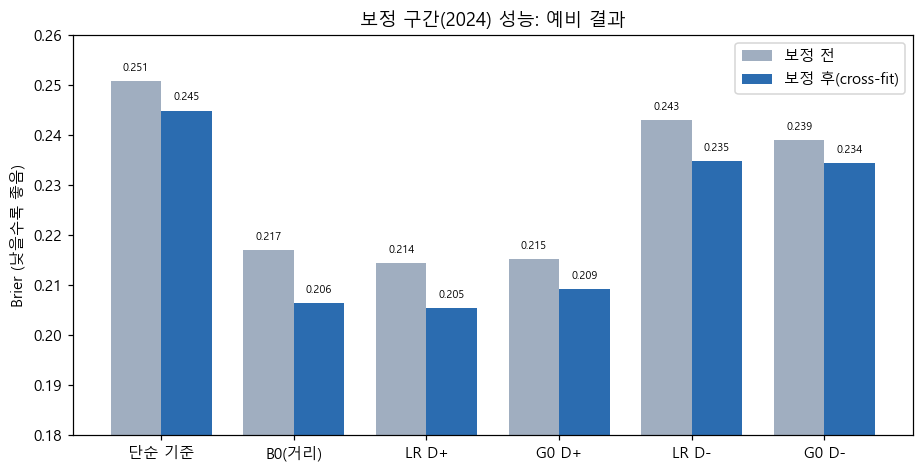

In [5]:
order = [("simple", "dplus", "단순 기준"), ("b0", "dplus", "B0(거리)"), ("lr", "dplus", "LR D+"), ("g0", "dplus", "G0 D+"), ("lr", "dminus", "LR D-"), ("g0", "dminus", "G0 D-")]
x = np.arange(len(order)); w = .38
raw = [tab[(tab.model == m) & (tab.dist == d)].brier_raw.iloc[0] for m, d, _ in order]
cf = [tab[(tab.model == m) & (tab.dist == d)].brier_crossfit.iloc[0] for m, d, _ in order]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar(x - w / 2, raw, w, label="보정 전", color="#a0aec0"); ax.bar(x + w / 2, cf, w, label="보정 후(cross-fit)", color="#2b6cb0")
for i, (r, c) in enumerate(zip(raw, cf)):
    ax.text(i - w / 2, r + .002, f"{r:.3f}", ha="center", fontsize=7); ax.text(i + w / 2, c + .002, f"{c:.3f}", ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([o[2] for o in order]); ax.set_ylim(.18, .26)
ax.set_ylabel("Brier (낮을수록 좋음)"); ax.set_title("보정 구간(2024) 성능: 예비 결과"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "03_모델_Brier_비교.png"); plt.show()

## 4. 보정 곡선 (예측 확률 vs 실제 초과율, 보정 구간)

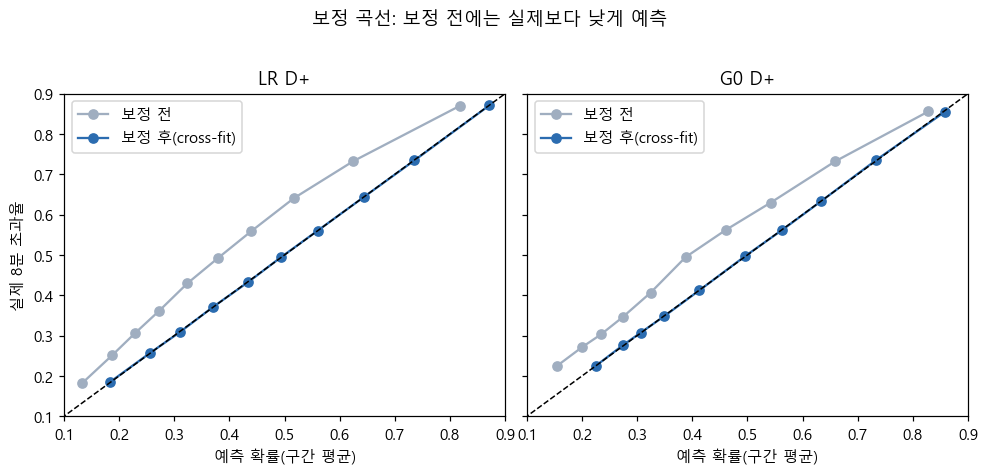

In [6]:
c = calib[(calib.train_years == "2019-2022") & (calib.calib_months == "1-12") & (calib.split == "calib") & (calib.dist == "dplus") & (calib.model.isin(["lr", "g0"]))]
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
for ax, m, t in zip(axs, ["lr", "g0"], ["LR D+", "G0 D+"]):
    for stage, col, lab in [("raw", "#a0aec0", "보정 전"), ("crossfit", "#2b6cb0", "보정 후(cross-fit)")]:
        s = c[(c.model == m) & (c.stage == stage)]
        ax.plot(s.mean_p, s.obs_rate, marker="o", color=col, label=lab)
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlim(.1, .9); ax.set_ylim(.1, .9)
    ax.set_xlabel("예측 확률(구간 평균)"); ax.set_title(t); ax.legend()
axs[0].set_ylabel("실제 8분 초과율")
fig.suptitle("보정 곡선: 보정 전에는 실제보다 낮게 예측", y=1.02); fig.tight_layout(); fig.savefig(OUT / "04_보정곡선.png", bbox_inches="tight"); plt.show()

## 5. 학습 구간·보정 구간 민감도 (D-015)

In [7]:
v = metrics[(metrics.group == "all") & (metrics.split == "calib") & (metrics.dist.isin(["dplus", "dminus"]))].copy()
v["지표"] = v.stage
piv = v[v.stage.isin(["raw", "crossfit"])].pivot_table(index=["model", "dist", "stage"], columns="variant", values=["brier", "citl"]).round(4)
piv.to_csv(TBL / "변형_비교_학습구간_보정구간.csv", encoding="utf-8-sig")
piv

brier                      \
variant                2019-2022 / 보정 1-12 2019-2022 / 보정 2-12   
model  dist   stage                                              
b0     dplus  crossfit              0.2064              0.2075   
              raw                   0.2170              0.2194   
g0     dminus crossfit              0.2345              0.2353   
              raw                   0.2390              0.2401   
       dplus  crossfit              0.2092              0.2106   
              raw                   0.2153              0.2173   
lr     dminus crossfit              0.2349              0.2355   
              raw                   0.2430              0.2440   
       dplus  crossfit              0.2055              0.2068   
              raw                   0.2145              0.2166   
simple dplus  crossfit              0.2449              0.2451   
              raw                   0.2507              0.2521   

                                                          citl  \
variant                2021-2022 / 보정 1-12 2019-2022 / 보정 1-12   
model  dist   stage                                              
b0     dplus  crossfit              0.2064             -0.0001   
              raw                   0.2112              0.4031   
g0     dminus crossfit              0.2340              0.0001   
              raw                   0.2352              0.2661   
       dplus  crossfit              0.2101             -0.0000   
              raw                   0.2115              0.3743   
lr     dminus crossfit              0.2351             -0.0001   
              raw                   0.2368              0.3863   
       dplus  crossfit              0.2067             -0.0002   
              raw                   0.2090              0.4435   
simple dplus  crossfit              0.2449             -0.0001   
              raw                   0.2468              0.2988   

                                                                
variant                2019-2022 / 보정 2-12 2021-2022 / 보정 1-12  
model  dist   stage                                             
b0     dplus  crossfit             -0.0001             -0.0001  
              raw                   0.4424              0.1860  
g0     dminus crossfit             -0.0000             -0.0001  
              raw                   0.2670              0.0286  
       dplus  crossfit              0.0001             -0.0003  
              raw                   0.3887              0.1638  
lr     dminus crossfit             -0.0001             -0.0001  
              raw                   0.3924              0.1016  
       dplus  crossfit             -0.0002             -0.0003  
              raw                   0.4670              0.2121  
simple dplus  crossfit             -0.0000             -0.0001  
              raw                   0.3272             -0.0013

## 7. 튜터링용 복사

In [8]:
import shutil
SEL = {
    "2_일변량": {"02_연도별_8분초과율.png": "2-3_연도별_8분초과율.png"},
    "4_모델결과": {"03_모델_Brier_비교.png": "4-1_Brier_비교.png", "04_보정곡선.png": "4-2_보정곡선.png"},
}
TSEL = ["모델_성능_보정구간_기본.csv", "변형_비교_학습구간_보정구간.csv", "연도별_8분초과율_안전센터.csv"]
for base in (Path("발표자료/중간발표"),):
    for stage, files in SEL.items():
        (base / "그래프" / stage).mkdir(parents=True, exist_ok=True)
        for src, dst in files.items():
            shutil.copy(OUT / src, base / "그래프" / stage / dst)
    (base / "표").mkdir(parents=True, exist_ok=True)
    for t in TSEL:
        shutil.copy(TBL / t, base / "표" / t)
sorted(p.name for p in OUT.glob("*.png"))

['01_정제_깔때기.png', '02_연도별_8분초과율.png', '03_모델_Brier_비교.png', '04_보정곡선.png']